# FlightOps ML — Top 50 Hubs Deep Domain Exploratory Data Analysis (EDA)

> **Dataset Universe:** 5,396,184 commercial scheduled domestic flights originating at the Top 50 US hub airports across calendar year 2025.
> **Target:** Binary departure delay indicator `dep_del15` ($\ge 15$ minutes late).
> **Prediction Horizon:** Strict cutoff at **2 hours prior to scheduled departure** ($T_{\text{cutoff}} = T_{\text{dep}} - 2\text{ hours}$ in UTC).

This notebook visualizes and quantifies the operational, network, and environmental delay drivers using **Pandas**, **Seaborn**, and **Matplotlib** directly from PostgreSQL.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from flightops_ml.ingestion.loader import database_connection

# Set global plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.titlesize": 16,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 150,
})

conn = database_connection()
print("Connected to PostgreSQL (flightops) successfully!")

Connected to PostgreSQL (flightops) successfully!


## 1. The Aviation Diurnal Delay Cascade (Departure Hour 00–23)

In commercial airline operations, delays compound throughout the day as turn-around buffer times evaporate. Notice the clean curve: early morning flights (06:00) start with fresh aircraft and have a delay rate under **7%**, while late evening flights (20:00) exceed **31%** due to downstream propagation.

C:\Users\zeyad\AppData\Local\Temp\ipykernel_3580\2317112893.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_diurnal = pd.read_sql(query_diurnal, conn)


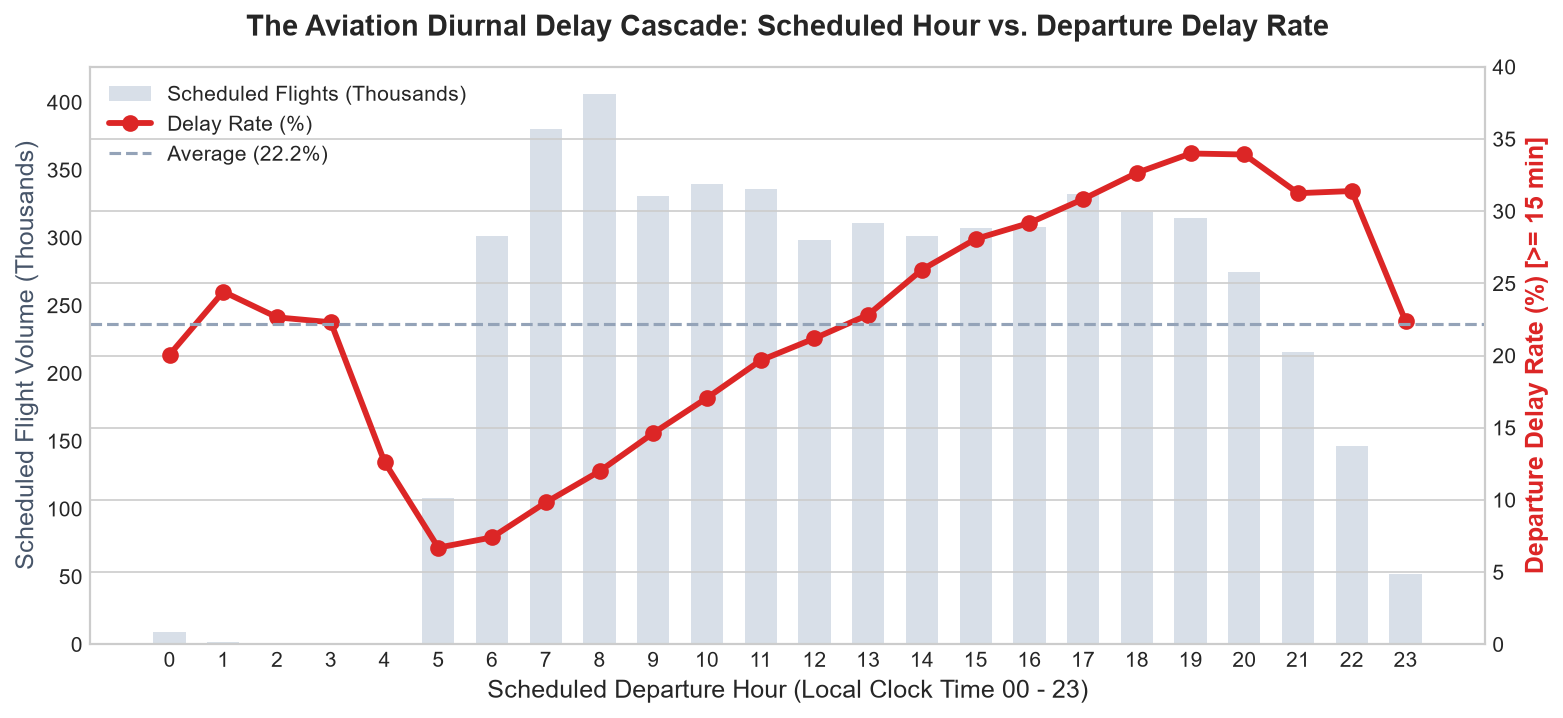

,dep_hour,total_flights,delayed_flights,delay_rate_pct
0,0,9301,1867,20.07
1,1,1457,356,24.43
2,2,468,106,22.65
3,3,520,116,22.31
4,4,190,24,12.63
5,5,107722,7218,6.70
6,6,301381,22320,7.41
7,7,380442,37385,9.83
8,8,405830,48651,11.99
9,9,331190,48468,14.63


In [2]:
query_diurnal = """
    SELECT 
        dep_hour,
        COUNT(*) as total_flights,
        SUM(dep_del15) as delayed_flights,
        ROUND(AVG(dep_del15)::numeric * 100, 2) as delay_rate_pct,
        ROUND(COUNT(*)::numeric / SUM(COUNT(*)) OVER () * 100, 2) as volume_pct
    FROM public.vw_gold_top50_baseline
    GROUP BY dep_hour
    ORDER BY dep_hour ASC;
"""
df_diurnal = pd.read_sql(query_diurnal, conn)

fig, ax1 = plt.subplots(figsize=(12, 5))

# Volume bar chart (left axis)
ax1.bar(df_diurnal["dep_hour"], df_diurnal["total_flights"] / 1000.0, color="#cbd5e1", alpha=0.75, width=0.6, label="Scheduled Flights (Thousands)")
ax1.set_xlabel("Scheduled Departure Hour (Local Clock Time 00 - 23)")
ax1.set_ylabel("Scheduled Flight Volume (Thousands)", color="#475569")
ax1.set_xticks(range(0, 24))
ax1.grid(False)

# Delay rate line (right axis)
ax2 = ax1.twinx()
ax2.plot(df_diurnal["dep_hour"], df_diurnal["delay_rate_pct"], color="#dc2626", marker="o", linewidth=2.8, markersize=7, label="Delay Rate (%)")
ax2.set_ylabel("Departure Delay Rate (%) [>= 15 min]", color="#dc2626", fontweight="bold")
ax2.set_ylim(0, 40)
ax2.axhline(df_diurnal["delay_rate_pct"].mean(), color="#94a3b8", linestyle="--", label=f"Average ({df_diurnal['delay_rate_pct'].mean():.1f}%)")

plt.title("The Aviation Diurnal Delay Cascade: Scheduled Hour vs. Departure Delay Rate", pad=15, fontweight="bold")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
plt.show()

df_diurnal[["dep_hour", "total_flights", "delayed_flights", "delay_rate_pct"]].head(10)

## 2. Operating Carrier Delay Hierarchy & Volume Share

How do the 14 operating carriers compare across the Top 50 hubs? Notice the spread: from punctual regional carriers down to ultra-low-cost carriers experiencing over 30% delay rates.

C:\Users\zeyad\AppData\Local\Temp\ipykernel_3580\3015085135.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_carrier = pd.read_sql(query_carrier, conn)


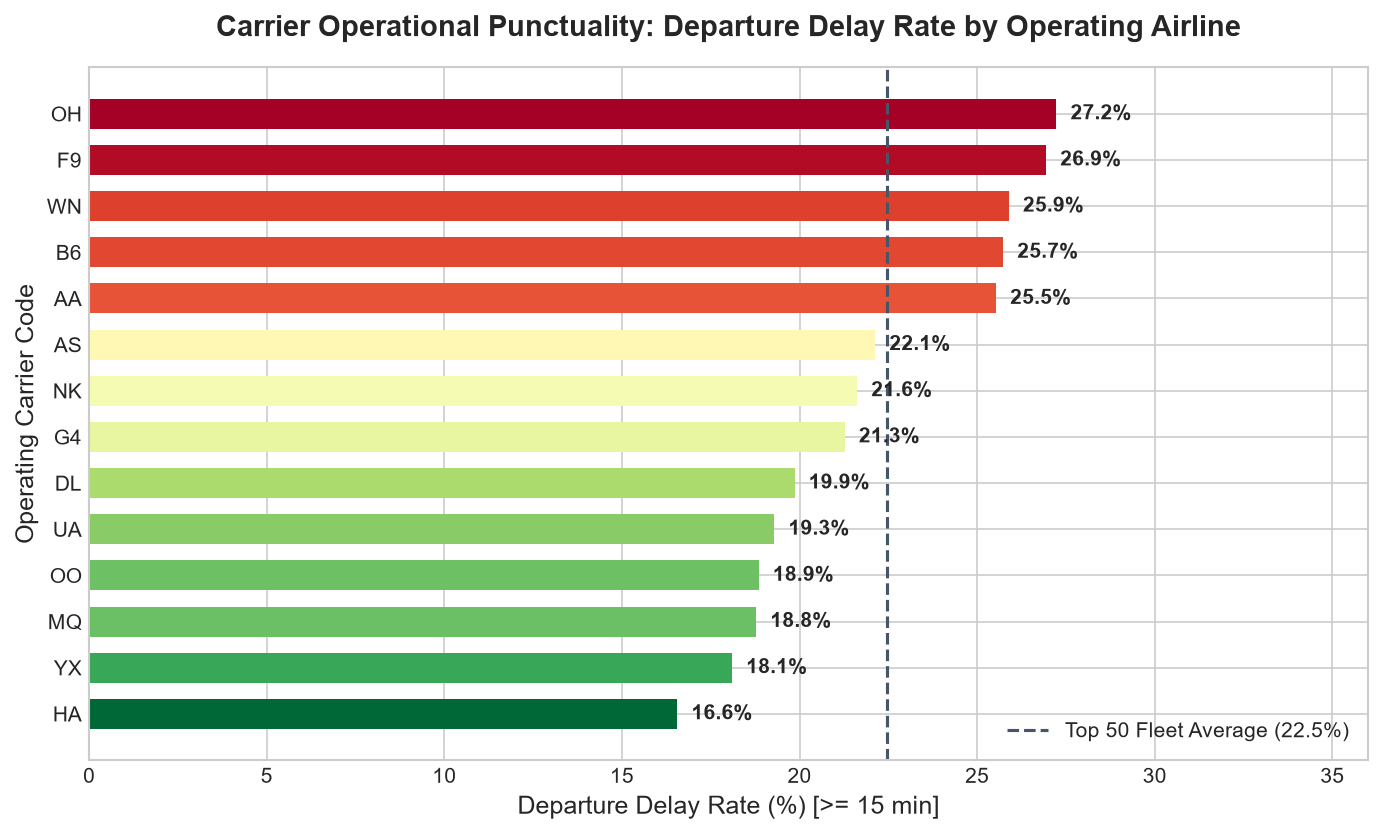

In [3]:
query_carrier = """
    SELECT 
        op_unique_carrier,
        COUNT(*) as total_flights,
        SUM(dep_del15) as delayed_flights,
        ROUND(AVG(dep_del15)::numeric * 100, 2) as delay_rate_pct,
        ROUND(COUNT(*)::numeric / SUM(COUNT(*)) OVER () * 100, 2) as volume_pct
    FROM public.vw_gold_top50_baseline
    GROUP BY op_unique_carrier
    ORDER BY delay_rate_pct ASC;
"""
df_carrier = pd.read_sql(query_carrier, conn)

fig, ax = plt.subplots(figsize=(11, 6))
norm = plt.Normalize(df_carrier["delay_rate_pct"].min(), df_carrier["delay_rate_pct"].max())
colors = plt.cm.RdYlGn_r(norm(df_carrier["delay_rate_pct"]))

bars = ax.barh(df_carrier["op_unique_carrier"], df_carrier["delay_rate_pct"], color=colors, height=0.65)
ax.axvline(22.45, color="#475569", linestyle="--", linewidth=1.5, label="Top 50 Fleet Average (22.5%)")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.4, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va="center", fontsize=10, fontweight="bold")

ax.set_xlim(0, 36)
ax.set_xlabel("Departure Delay Rate (%) [>= 15 min]")
ax.set_ylabel("Operating Carrier Code")
ax.set_title("Carrier Operational Punctuality: Departure Delay Rate by Operating Airline", pad=15, fontweight="bold")
ax.legend(loc="lower right")
plt.show()

## 3. Origin Hub Congestion Spectrum (Top 50 Airports)

Which hubs are the bottlenecks in the national airspace system? Compare congested hubs (e.g. Newark, LaGuardia, O'Hare) against punctual mountain/coastal hubs.

C:\Users\zeyad\AppData\Local\Temp\ipykernel_3580\2102219823.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_hubs = pd.read_sql(query_hubs, conn)


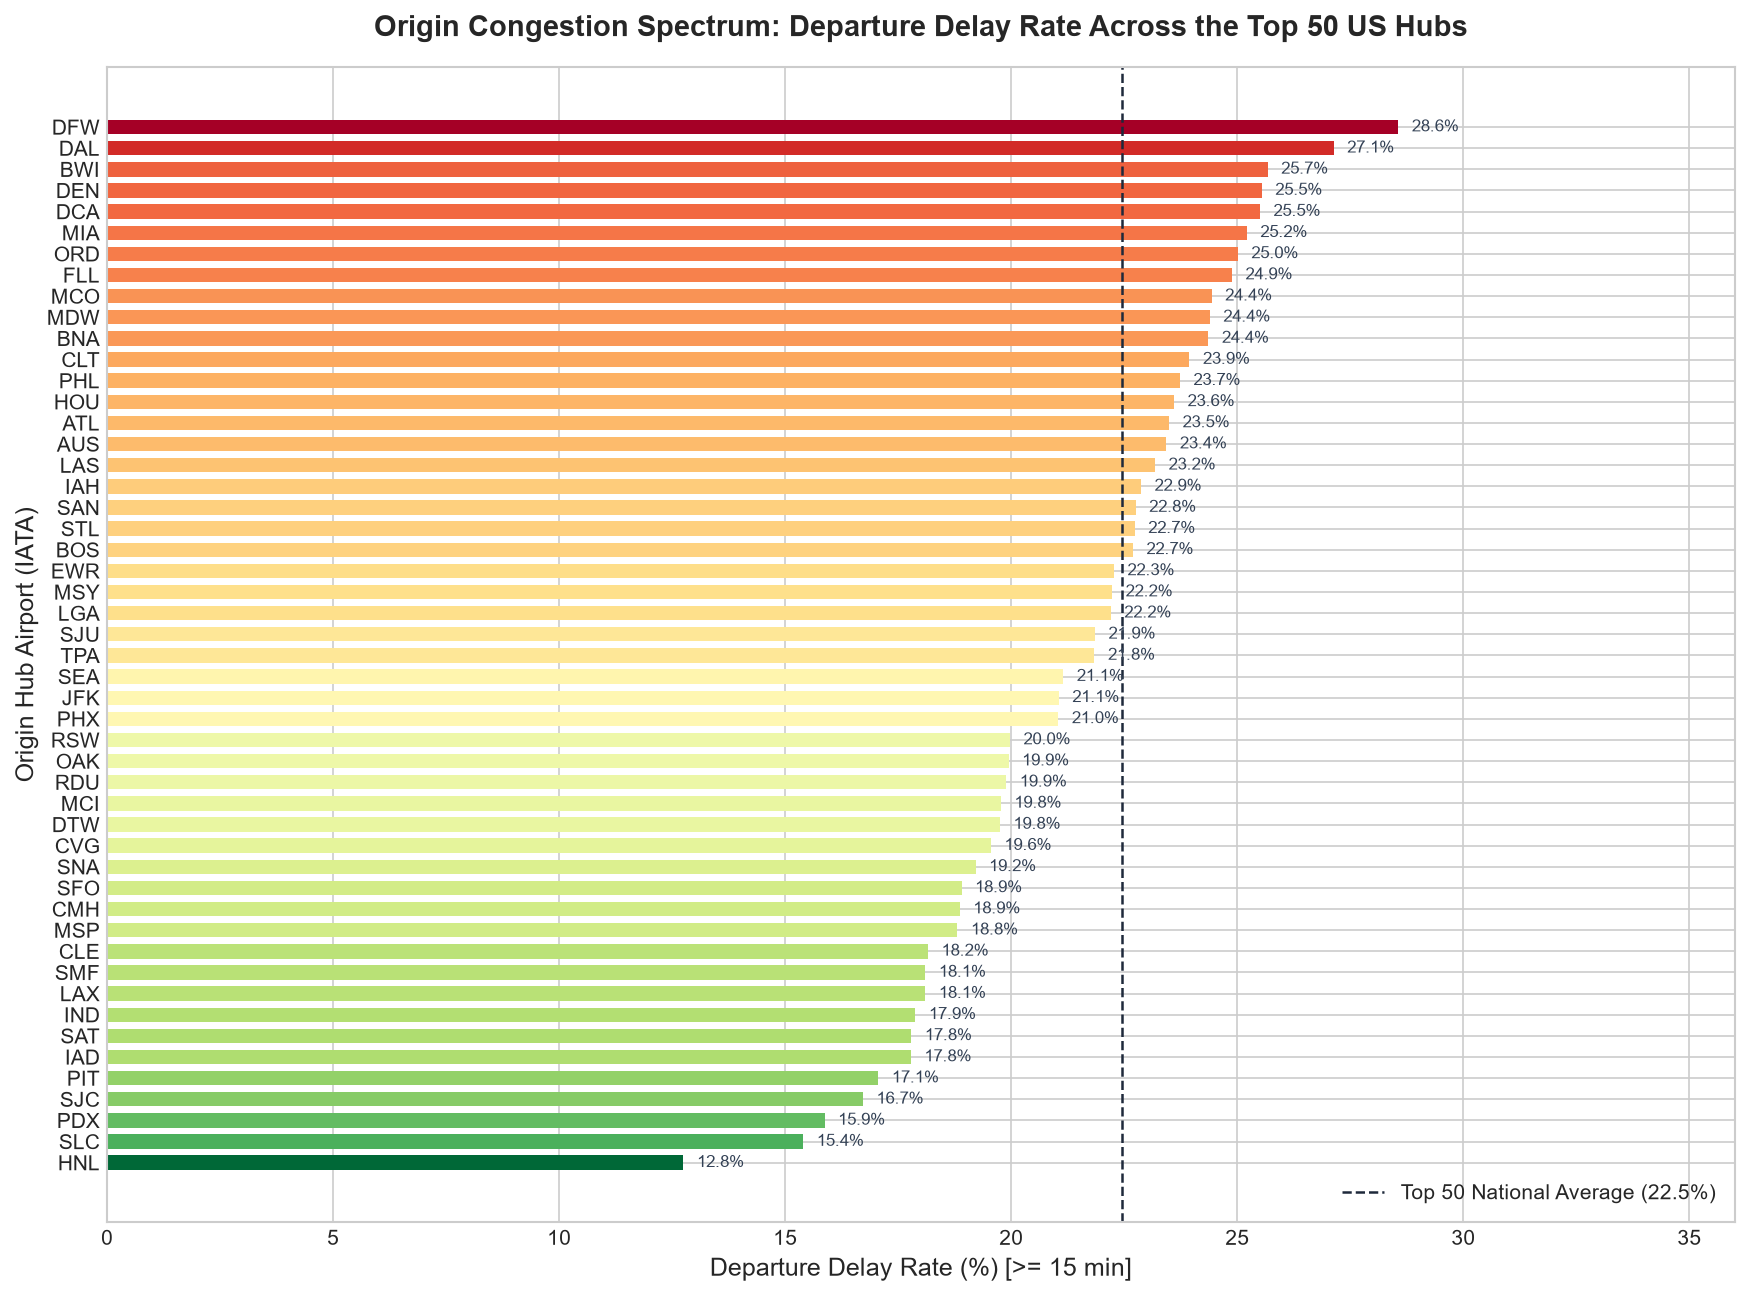

In [4]:
query_hubs = """
    SELECT 
        origin,
        COUNT(*) as total_flights,
        ROUND(AVG(dep_del15)::numeric * 100, 2) as delay_rate_pct
    FROM public.vw_gold_top50_baseline
    GROUP BY origin
    ORDER BY delay_rate_pct DESC;
"""
df_hubs = pd.read_sql(query_hubs, conn)

fig, ax = plt.subplots(figsize=(14, 10))
norm = plt.Normalize(df_hubs["delay_rate_pct"].min(), df_hubs["delay_rate_pct"].max())
colors = plt.cm.RdYlGn_r(norm(df_hubs["delay_rate_pct"]))[::-1]

bars = ax.barh(df_hubs["origin"][::-1], df_hubs["delay_rate_pct"][::-1], color=colors, height=0.68)
ax.axvline(22.45, color="#1e293b", linestyle="--", linewidth=1.2, label="Top 50 National Average (22.5%)")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va="center", fontsize=8, color="#334155")

ax.set_xlim(0, 36)
ax.set_xlabel("Departure Delay Rate (%) [>= 15 min]")
ax.set_ylabel("Origin Hub Airport (IATA)")
ax.set_title("Origin Congestion Spectrum: Departure Delay Rate Across the Top 50 US Hubs", pad=15, fontweight="bold")
ax.legend(loc="lower right")
plt.show()

## 4. Seasonal Base-Rate Drift & Partition Boundaries

Here we visualize the monthly progression across **Train** (Jan–Aug: 22.9%), **Validation** (Sep–Oct: 19.0%), and **Test** (Nov–Dec: 24.2%). Notice how September and October experience a substantial operational reprieve due to calm autumn weather before the holiday surge.

C:\Users\zeyad\AppData\Local\Temp\ipykernel_3580\1159852608.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_season = pd.read_sql(query_season, conn)


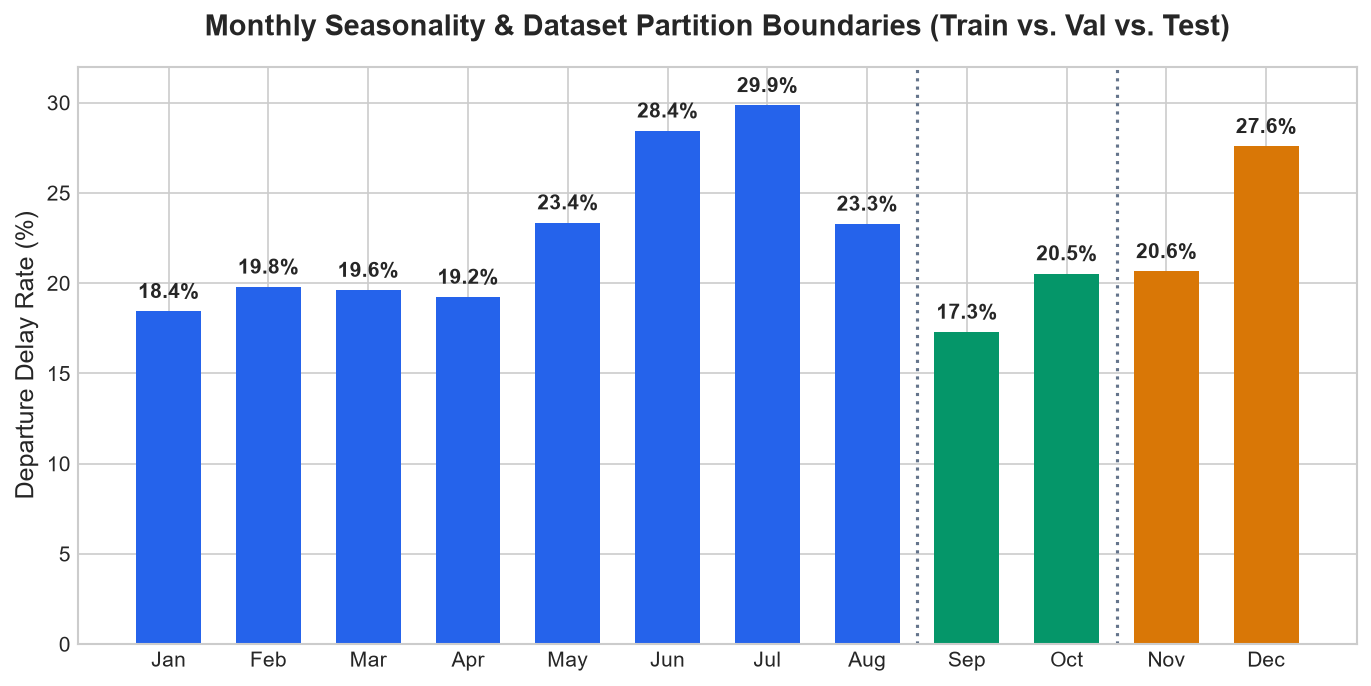

In [5]:
query_season = """
    SELECT 
        month,
        dataset_split,
        COUNT(*) as total_flights,
        SUM(dep_del15) as delayed_flights,
        ROUND(AVG(dep_del15)::numeric * 100, 2) as delay_rate_pct
    FROM public.vw_gold_top50_baseline
    GROUP BY month, dataset_split
    ORDER BY month ASC;
"""
df_season = pd.read_sql(query_season, conn)
month_names = ["", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df_season["month_label"] = df_season["month"].map(lambda m: month_names[m])

fig, ax = plt.subplots(figsize=(11, 5))
split_palette = {"train": "#2563eb", "validation": "#059669", "test": "#d97706"}
bars = ax.bar(
    df_season["month_label"], 
    df_season["delay_rate_pct"], 
    color=[split_palette[s] for s in df_season["dataset_split"]],
    width=0.65
)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.5, f"{h:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.axvline(7.5, color="#64748b", linestyle=":", linewidth=1.5)
ax.axvline(9.5, color="#64748b", linestyle=":", linewidth=1.5)
ax.set_ylim(0, 32)
ax.set_ylabel("Departure Delay Rate (%)")
ax.set_title("Monthly Seasonality & Dataset Partition Boundaries (Train vs. Val vs. Test)", pad=15, fontweight="bold")
plt.show()

## 5. Bivariate Weather Delay Lift (At $T-2\text{ hours}$ Cutoff)

What is the empirical delay lift when terminal weather is adverse at the 2-hour pre-departure cutoff? Notice the dramatic impact of active thunderstorms and snow on delay risk.

C:\Users\zeyad\AppData\Local\Temp\ipykernel_3580\3006894195.py:46: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_wx = pd.read_sql(query_weather, conn)


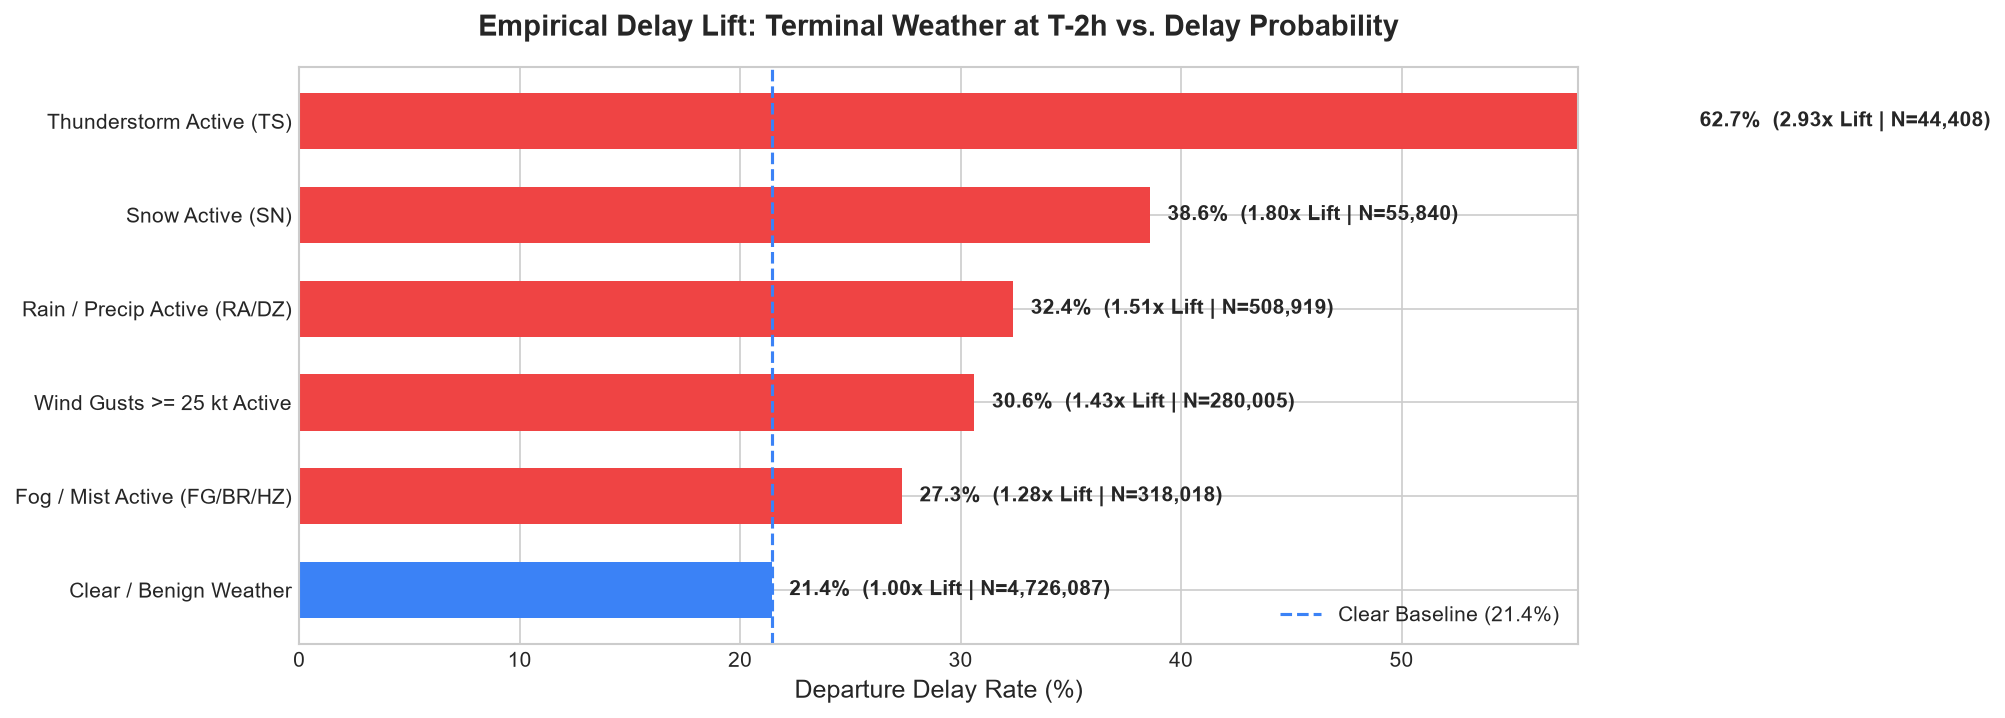

In [6]:
query_weather = """
    SELECT 
        'Clear / Benign Weather' as condition_name,
        ROUND(AVG(dep_del15)::numeric * 100, 2) as delay_rate_pct,
        COUNT(*) as sample_size
    FROM public.vw_gold_top50_weather
    WHERE weather_obs_time_utc IS NOT NULL
      AND weather_has_precip = 0 AND weather_has_fog_haze = 0
    UNION ALL
    SELECT 
        'Fog / Mist Active (FG/BR/HZ)',
        ROUND(AVG(dep_del15)::numeric * 100, 2),
        COUNT(*)
    FROM public.vw_gold_top50_weather
    WHERE weather_obs_time_utc IS NOT NULL AND weather_has_fog_haze = 1
    UNION ALL
    SELECT 
        'Rain / Precip Active (RA/DZ)',
        ROUND(AVG(dep_del15)::numeric * 100, 2),
        COUNT(*)
    FROM public.vw_gold_top50_weather
    WHERE weather_obs_time_utc IS NOT NULL AND weather_has_precip = 1
    UNION ALL
    SELECT 
        'Wind Gusts >= 25 kt Active',
        ROUND(AVG(dep_del15)::numeric * 100, 2),
        COUNT(*)
    FROM public.vw_gold_top50_weather
    WHERE weather_obs_time_utc IS NOT NULL AND weather_wind_gust_kt >= 25
    UNION ALL
    SELECT 
        'Snow Active (SN)',
        ROUND(AVG(dep_del15)::numeric * 100, 2),
        COUNT(*)
    FROM public.vw_gold_top50_weather
    WHERE weather_obs_time_utc IS NOT NULL AND weather_has_snow = 1
    UNION ALL
    SELECT 
        'Thunderstorm Active (TS)',
        ROUND(AVG(dep_del15)::numeric * 100, 2),
        COUNT(*)
    FROM public.vw_gold_top50_weather
    WHERE weather_obs_time_utc IS NOT NULL AND weather_has_thunderstorm = 1
    ORDER BY delay_rate_pct ASC;
"""
df_wx = pd.read_sql(query_weather, conn)
baseline_rate = df_wx.loc[df_wx["condition_name"] == "Clear / Benign Weather", "delay_rate_pct"].values[0]

fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#3b82f6" if r == baseline_rate else "#ef4444" for r in df_wx["delay_rate_pct"]]
bars = ax.barh(df_wx["condition_name"], df_wx["delay_rate_pct"], color=colors, height=0.6)
ax.axvline(baseline_rate, color="#3b82f6", linestyle="--", linewidth=1.5, label=f"Clear Baseline ({baseline_rate:.1f}%)")

for bar, (_, row) in zip(bars, df_wx.iterrows()):
    w = bar.get_width()
    lift = w / baseline_rate
    ax.text(
        w + 0.8, bar.get_y() + bar.get_height() / 2,
        f"{w:.1f}%  ({lift:.2f}x Lift | N={row['sample_size']:,})",
        va="center", fontsize=10, fontweight="bold"
    )

ax.set_xlim(0, 58)
ax.set_xlabel("Departure Delay Rate (%)")
ax.set_title("Empirical Delay Lift: Terminal Weather at T-2h vs. Delay Probability", pad=15, fontweight="bold")
ax.legend(loc="lower right")
plt.show()

## 6. Compound Risk: Time of Day $\times$ Terminal Weather (Heatmap)

When adverse weather collides with peak operational hours, delays explode. In the heatmap below, notice how an evening flight with an active thunderstorm approaches a **60% delay rate**, compared to **14%** for an early morning flight in clear weather.

C:\Users\zeyad\AppData\Local\Temp\ipykernel_3580\412114907.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_hm = pd.read_sql(query_heatmap, conn)


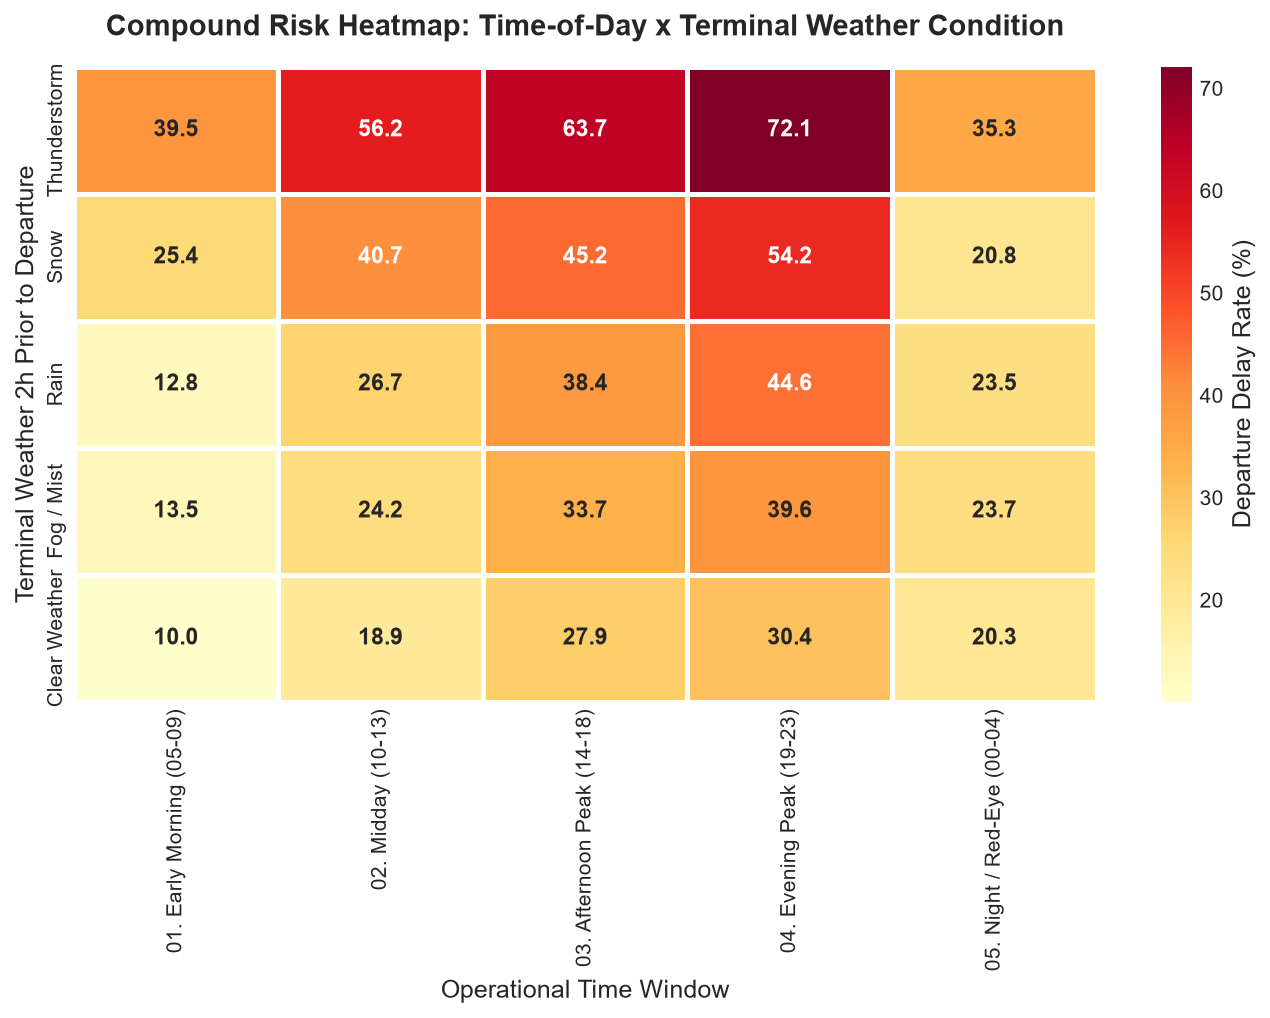

In [7]:
query_heatmap = """
    SELECT 
        CASE 
            WHEN dep_hour BETWEEN 5 AND 9 THEN '01. Early Morning (05-09)'
            WHEN dep_hour BETWEEN 10 AND 13 THEN '02. Midday (10-13)'
            WHEN dep_hour BETWEEN 14 AND 18 THEN '03. Afternoon Peak (14-18)'
            WHEN dep_hour BETWEEN 19 AND 23 THEN '04. Evening Peak (19-23)'
            ELSE '05. Night / Red-Eye (00-04)'
        END as day_period,
        CASE 
            WHEN weather_has_thunderstorm = 1 THEN 'Thunderstorm'
            WHEN weather_has_snow = 1 THEN 'Snow'
            WHEN weather_has_precip = 1 THEN 'Rain'
            WHEN weather_has_fog_haze = 1 THEN 'Fog / Mist'
            ELSE 'Clear Weather'
        END as weather_condition,
        ROUND(AVG(dep_del15)::numeric * 100, 2) as delay_rate_pct
    FROM public.vw_gold_top50_weather
    WHERE weather_obs_time_utc IS NOT NULL
    GROUP BY 1, 2;
"""
df_hm = pd.read_sql(query_heatmap, conn)
pivot = df_hm.pivot(index="weather_condition", columns="day_period", values="delay_rate_pct")
pivot = pivot.reindex(["Thunderstorm", "Snow", "Rain", "Fog / Mist", "Clear Weather"])

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(
    pivot, 
    annot=True, 
    fmt=".1f", 
    cmap="YlOrRd", 
    cbar_kws={"label": "Departure Delay Rate (%)"},
    linewidths=1.5,
    ax=ax,
    annot_kws={"size": 11, "weight": "bold"}
)
ax.set_title("Compound Risk Heatmap: Time-of-Day x Terminal Weather Condition", pad=15, fontweight="bold")
ax.set_xlabel("Operational Time Window")
ax.set_ylabel("Terminal Weather 2h Prior to Departure")
plt.show()

---
## 7. Weekly Operational Cycle (Day of Week)

Commercial aviation operations fluctuate across the week between business travel departures and weekend leisure return surges.

The chart and table below show the observed departure delay prevalence and flight volume from Monday through Sunday across all 4,510,362 training and validation flights (`dataset_split IN ('train', 'validation')`). Notice that **Sunday departures experience a 25.5% delay rate**, compared to **17.9% on Tuesday** — an observed spread of 7.5 percentage points (+41.9% relative increase in delay rate).

*Caveat:* These statistics represent descriptive aggregate associations across network operations. They do not claim that day-of-week alone causally drives delays, nor do they represent like-for-like adjusted comparisons across identical routes or weather conditions.

In [ ]:
query_dow = """
    SELECT 
        day_of_week,
        COUNT(*) as total_flights,
        SUM(dep_del15) as delayed_flights,
        ROUND(AVG(dep_del15)::numeric * 100, 2) as delay_rate_pct,
        ROUND(COUNT(*)::numeric / SUM(COUNT(*)) OVER () * 100, 2) as volume_pct
    FROM public.vw_gold_top50_baseline
    WHERE dataset_split IN ('train', 'validation')
    GROUP BY day_of_week
    ORDER BY day_of_week ASC;
"""
df_dow = pd.read_sql(query_dow, conn)
dow_names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
df_dow["day_name"] = df_dow["day_of_week"].map(dow_names)

fig, ax = plt.subplots(figsize=(10, 4.5))
norm = plt.Normalize(df_dow["delay_rate_pct"].min(), df_dow["delay_rate_pct"].max())
colors = plt.cm.RdYlGn_r(norm(df_dow["delay_rate_pct"]))

bars = ax.bar(df_dow["day_name"], df_dow["delay_rate_pct"], color=colors, width=0.6)
ax.axhline(df_dow["delay_rate_pct"].mean(), color="#64748b", linestyle="--", linewidth=1.2, label=f"Weekly Mean ({df_dow['delay_rate_pct'].mean():.1f}%)")

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.4, f"{h:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_ylim(0, 32)
ax.set_ylabel("Departure Delay Rate (%) [>= 15 min]")
ax.set_xlabel("Day of Week (Monday = 1, Sunday = 7)")
ax.set_title("Weekly Delay Rate Cycle (Training & Validation Cohort, 4.51M Flights)", pad=15, fontweight="bold")
ax.legend(loc="upper left")
plt.show()

display(df_dow[["day_of_week", "day_name", "total_flights", "delayed_flights", "delay_rate_pct", "volume_pct"]])

---
## 8. Bidirectional Route Corridors (JFK–LAX & ORD–LGA)

High-density route corridors often display pronounced directional asymmetries in scheduled duration and departure punctuality.

The table below reports directional sample sizes, scheduled block durations, and departure delay rates across two major domestic trunk corridors on the training and validation splits:
- **Transcontinental Trunk (JFK $\leftrightarrow$ LAX, 2,475 mi):** Westbound flights (JFK $\rightarrow$ LAX) have an average scheduled block duration of **375.8 minutes**, compared to **332.0 minutes** eastbound (LAX $\rightarrow$ JFK) — an average block difference of 43.8 minutes. Concurrently, LAX $\rightarrow$ JFK exhibits an observed delay rate of **20.60%** versus **15.68%** westbound.
- **Midwest–Northeast Trunk (ORD $\leftrightarrow$ LGA, 733 mi):** LGA $\rightarrow$ ORD scheduled block time averages **162.3 minutes** versus **134.7 minutes** eastbound (27.6 minute difference). ORD $\rightarrow$ LGA exhibits a higher departure delay rate (**24.99%** vs. **20.67%**).

*Caveat:* These figures are descriptive observational summaries. They do not constitute formal causal proof of jet-stream wind impacts or local airspace slot bottlenecks.

In [ ]:
query_routes = """
    SELECT 
        t.airport_code as origin,
        r.airport_code as dest,
        COUNT(*) as n_flights,
        ROUND(AVG(f.distance)::numeric, 0) as distance_mi,
        ROUND(AVG(f.crs_elapsed_time_clean)::numeric, 1) as avg_block_min,
        SUM(f.dep_del15) as delayed_flights,
        ROUND(AVG(f.dep_del15)::numeric * 100, 2) as delay_rate_pct
    FROM public.gold_features f
    JOIN public.top_50_airports t ON f.origin_airport_id = t.origin_airport_id
    JOIN public.airport_reference r ON f.dest_airport_id = r.airport_id AND r.is_latest = TRUE
    WHERE f.dataset_split IN ('train', 'validation')
      AND ((t.airport_code = 'JFK' AND r.airport_code = 'LAX') OR (t.airport_code = 'LAX' AND r.airport_code = 'JFK')
        OR (t.airport_code = 'ORD' AND r.airport_code = 'LGA') OR (t.airport_code = 'LGA' AND r.airport_code = 'ORD'))
    GROUP BY t.airport_code, r.airport_code
    ORDER BY 
        CASE WHEN t.airport_code IN ('JFK', 'LAX') THEN 1 ELSE 2 END,
        t.airport_code ASC;
"""
df_routes = pd.read_sql(query_routes, conn)
display(df_routes)

---
## 9. Continuous Predictor Diagnostics & Sensor Characteristics

Before training supervised algorithms, continuous predictors must be audited for plausible ranges, outlier profiles, missingness, and measurement ceiling artifacts.

The diagnostic table below summarizes the distribution percentiles and missingness across 4,510,362 training and validation flights:
- **Flight Physicals:** Scheduled distance spans 67 to 5,095 miles (median 761 mi); scheduled elapsed duration spans 10 to 739 minutes (median 140 min). Both show zero missingness in the cleaned Gold schema.
- **Surface Meteorological Sensors:** Temperature (median 68°F), dew point (median 52°F), and altimeter pressure (median 30.02 inHg) exhibit less than 0.02% sensor nulls.
- **Visibility Ceiling Artifact:** Notice that **87.67% of visibility readings are recorded at exactly 10.0 statute miles**. Under standard US METAR automated weather observing systems (ASOS), reported visibility is capped at 10 SM in clear conditions. This creates a strongly ceiling-concentrated distribution, with the 1st percentile at 1.3 SM. Visibility impairment may therefore be more informative when examined using operationally meaningful ranges (for example, below 3–5 SM) than under an assumed linear relationship. This EDA establishes the distributional pattern, not which encoding or model performs best.

In [ ]:
query_diagnostics = """
    SELECT 
        'distance_mi' as feature_name,
        COUNT(*) as n_total,
        COUNT(distance) as n_valid,
        ROUND((1.0 - COUNT(distance)::numeric / COUNT(*)) * 100, 3) as missing_pct,
        ROUND(MIN(distance)::numeric, 1) as min_val,
        ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY distance)::numeric, 1) as p25,
        ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY distance)::numeric, 1) as p50_median,
        ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY distance)::numeric, 1) as p75,
        ROUND(PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY distance)::numeric, 1) as p99,
        ROUND(MAX(distance)::numeric, 1) as max_val,
        'N/A' as ceiling_10sm_pct
    FROM public.vw_gold_top50_baseline
    WHERE dataset_split IN ('train', 'validation')
    UNION ALL
    SELECT 
        'crs_elapsed_time_min',
        COUNT(*),
        COUNT(crs_elapsed_time_clean),
        ROUND((1.0 - COUNT(crs_elapsed_time_clean)::numeric / COUNT(*)) * 100, 3),
        ROUND(MIN(crs_elapsed_time_clean)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY crs_elapsed_time_clean)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY crs_elapsed_time_clean)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY crs_elapsed_time_clean)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY crs_elapsed_time_clean)::numeric, 1),
        ROUND(MAX(crs_elapsed_time_clean)::numeric, 1),
        'N/A'
    FROM public.vw_gold_top50_baseline
    WHERE dataset_split IN ('train', 'validation')
    UNION ALL
    SELECT 
        'weather_temp_f',
        COUNT(*),
        COUNT(weather_temp_f),
        ROUND((1.0 - COUNT(weather_temp_f)::numeric / COUNT(*)) * 100, 3),
        ROUND(MIN(weather_temp_f)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY weather_temp_f)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY weather_temp_f)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY weather_temp_f)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY weather_temp_f)::numeric, 1),
        ROUND(MAX(weather_temp_f)::numeric, 1),
        'N/A'
    FROM public.vw_gold_top50_weather
    WHERE dataset_split IN ('train', 'validation')
    UNION ALL
    SELECT 
        'weather_dew_point_f',
        COUNT(*),
        COUNT(weather_dew_point_f),
        ROUND((1.0 - COUNT(weather_dew_point_f)::numeric / COUNT(*)) * 100, 3),
        ROUND(MIN(weather_dew_point_f)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY weather_dew_point_f)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY weather_dew_point_f)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY weather_dew_point_f)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY weather_dew_point_f)::numeric, 1),
        ROUND(MAX(weather_dew_point_f)::numeric, 1),
        'N/A'
    FROM public.vw_gold_top50_weather
    WHERE dataset_split IN ('train', 'validation')
    UNION ALL
    SELECT 
        'weather_wind_speed_kt',
        COUNT(*),
        COUNT(weather_wind_speed_kt),
        ROUND((1.0 - COUNT(weather_wind_speed_kt)::numeric / COUNT(*)) * 100, 3),
        ROUND(MIN(weather_wind_speed_kt)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY weather_wind_speed_kt)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY weather_wind_speed_kt)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY weather_wind_speed_kt)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY weather_wind_speed_kt)::numeric, 1),
        ROUND(MAX(weather_wind_speed_kt)::numeric, 1),
        'N/A'
    FROM public.vw_gold_top50_weather
    WHERE dataset_split IN ('train', 'validation')
    UNION ALL
    SELECT 
        'weather_visibility_sm',
        COUNT(*),
        COUNT(weather_visibility_sm),
        ROUND((1.0 - COUNT(weather_visibility_sm)::numeric / COUNT(*)) * 100, 3),
        ROUND(MIN(weather_visibility_sm)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY weather_visibility_sm)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY weather_visibility_sm)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY weather_visibility_sm)::numeric, 1),
        ROUND(PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY weather_visibility_sm)::numeric, 1),
        ROUND(MAX(weather_visibility_sm)::numeric, 1),
        ROUND(COUNT(CASE WHEN weather_visibility_sm = 10.0 THEN 1 END)::numeric / NULLIF(COUNT(weather_visibility_sm), 0) * 100, 2)::text || '%'
    FROM public.vw_gold_top50_weather
    WHERE dataset_split IN ('train', 'validation')
    UNION ALL
    SELECT 
        'weather_altimeter_in_hg',
        COUNT(*),
        COUNT(weather_altimeter_in_hg),
        ROUND((1.0 - COUNT(weather_altimeter_in_hg)::numeric / COUNT(*)) * 100, 3),
        ROUND(MIN(weather_altimeter_in_hg)::numeric, 2),
        ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY weather_altimeter_in_hg)::numeric, 2),
        ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY weather_altimeter_in_hg)::numeric, 2),
        ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY weather_altimeter_in_hg)::numeric, 2),
        ROUND(PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY weather_altimeter_in_hg)::numeric, 2),
        ROUND(MAX(weather_altimeter_in_hg)::numeric, 2),
        'N/A'
    FROM public.vw_gold_top50_weather
    WHERE dataset_split IN ('train', 'validation');
"""
df_diag = pd.read_sql(query_diagnostics, conn)
display(df_diag)